Device: cpu
'fake_news_data.csv' not found -> generating a DEMO dataset (toy data).

Dataset shape: (300, 3)
Class balance (0 = real, 1 = fake):
 label
0    150
1    150
Name: count, dtype: int64

Sample rows:
                                                                                       text  label
     The ministry announced updated guidelines on 5G towers following public consultation.      0
Researchers reported modest progress on the election, according to the official statement.      1
            100% PROOF that vaccines is a government cover-up, they don't want you to know      0
      100% PROOF that climate policy is a government cover-up, they don't want you to know      1

Extracting TEXT features with DistilBERT ...


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Extracting IMAGE features with ResNet-18 ...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 42.5MB/s]


Text features : (300, 768) | Image features: (300, 512)
Train: 210 | Validation: 45 | Test: 45

Training the early-fusion network ...
Epoch   1 | train loss 0.5037 | val loss 0.3061
Epoch  10 | train loss 0.1837 | val loss 0.2318
Epoch  20 | train loss 0.0764 | val loss 0.4804
Epoch  30 | train loss 0.0468 | val loss 0.3436
Epoch  40 | train loss 0.0264 | val loss 0.7536
Epoch  50 | train loss 0.0313 | val loss 0.5353
Epoch  60 | train loss 0.0063 | val loss 0.8158


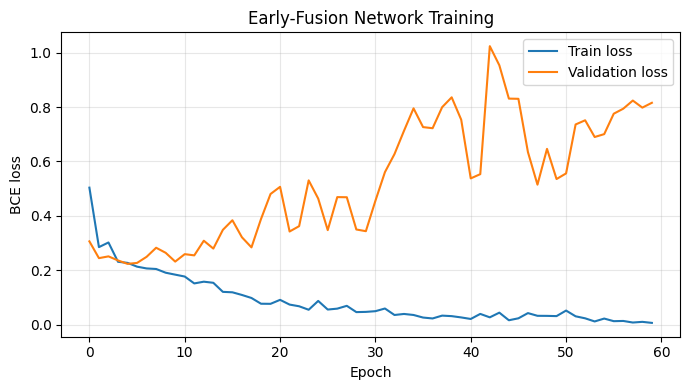


TEST SET RESULTS
            Model  Accuracy  Precision  Recall     F1  ROC-AUC
        Text only    0.8444     0.7586  1.0000 0.8627   0.8834
       Image only    0.8222     0.8500  0.7727 0.8095   0.9071
      Late fusion    0.8889     0.8148  1.0000 0.8980   0.9723
Early fusion (NN)    0.8222     0.7333  1.0000 0.8462   0.9862


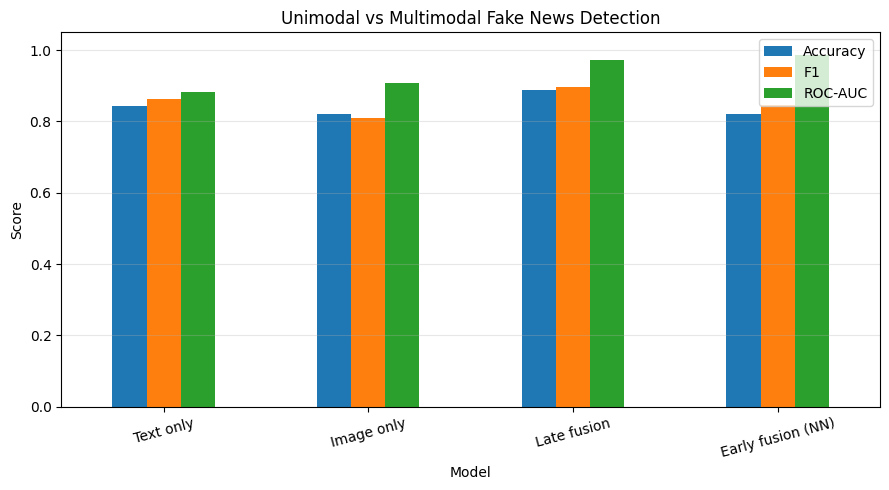

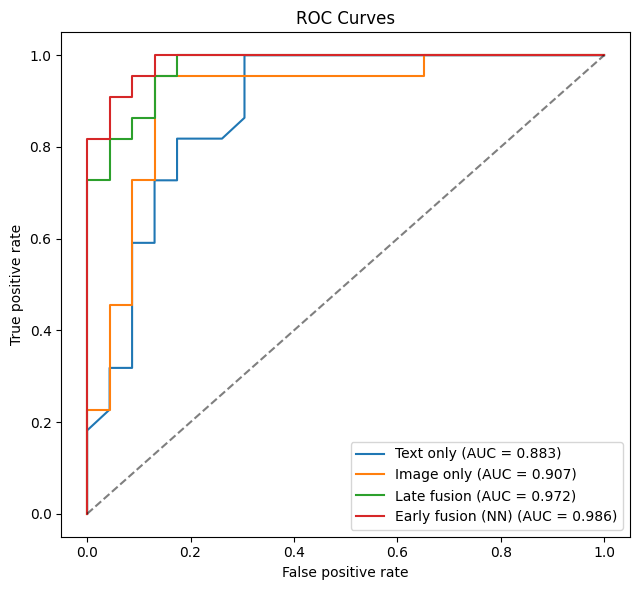

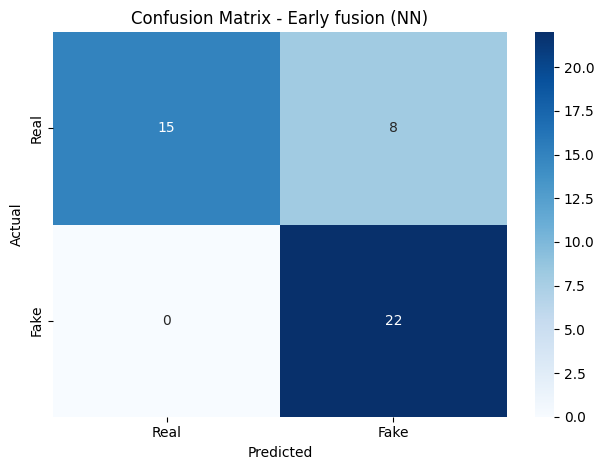

              precision    recall  f1-score   support

        Real       1.00      0.65      0.79        23
        Fake       0.73      1.00      0.85        22

    accuracy                           0.82        45
   macro avg       0.87      0.83      0.82        45
weighted avg       0.87      0.82      0.82        45


Example post : Researchers reported modest progress on the election, according to the official statement.
Prediction   : REAL  (P(fake) = 0.018)  | Actual: REAL

Conclusion: Fake news often shows up in BOTH what is written and what is shown. Combining text and image features (multimodal fusion) lets the model use evidence from each source, and usually beats either modality alone.


In [ ]:
"""
Assignment 10: Design a model to detect Fake News from Multimodal data.

Multimodal = TEXT (headline / post) + IMAGE (attached picture).

Pipeline:
  1. Load data (CSV with text, image_path, label) - or auto-generate a small DEMO dataset
  2. Text features  : DistilBERT embeddings (mean pooled)      -> 768 dims
  3. Image features : ResNet-18 (ImageNet pretrained) embeddings -> 512 dims
  4. Models compared:
        a) Text-only      (Logistic Regression on text embeddings)
        b) Image-only     (Logistic Regression on image embeddings)
        c) Late fusion    (average of the two probabilities)
        d) Early fusion   (neural network: text branch + image branch -> concatenate -> classify)
  5. Evaluation: accuracy, precision, recall, F1, ROC-AUC, confusion matrix, ROC curves
  6. predict_news(text, image_path) for new posts

HOW TO USE WITH REAL DATA
  Set DATA_CSV to a file with columns:  text, image_path, label   (label: 1 = fake, 0 = real)
  Suggested datasets: Fakeddit, MediaEval Verifying Multimedia Use, FakeNewsNet (with images).
  If DATA_CSV does not exist, a small synthetic DEMO dataset is generated so the code runs
  end to end. Demo accuracy is NOT meaningful - it only proves the pipeline works.

Install (Colab already has most of these):
    pip install torch torchvision transformers scikit-learn pandas numpy matplotlib seaborn pillow
"""

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import models, transforms
from transformers import AutoTokenizer, AutoModel

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve,
                             classification_report)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------
DATA_CSV = "fake_news_data.csv"       # columns: text, image_path, label
DEMO_IMAGE_DIR = "demo_images"
SEED = 42
EPOCHS = 60
BATCH_SIZE = 32
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
print("Device:", DEVICE)

# ==================================================================
# STEP 1: Load data (or build a demo dataset)
# ==================================================================
FAKE_TEXTS = [
    "SHOCKING: {x} secretly controls the world, media is hiding the truth!!!",
    "You won't believe what {x} did - doctors HATE this one trick!",
    "BREAKING: miracle cure for {x} banned by big pharma, share before it is deleted",
    "Leaked: {x} admits everything is a hoax, wake up people!!!",
    "100% PROOF that {x} is a government cover-up, they don't want you to know",
]
REAL_TEXTS = [
    "Officials said on Tuesday that {x} will be reviewed by the committee next month.",
    "A new study published in a peer-reviewed journal examines the effects of {x}.",
    "The ministry announced updated guidelines on {x} following public consultation.",
    "Local authorities confirmed that work on {x} will begin early next year.",
    "Researchers reported modest progress on {x}, according to the official statement.",
]
TOPICS = ["vaccines", "the election", "the new bridge", "5G towers", "the stock market",
          "the city budget", "climate policy", "the school program", "the energy grid"]


def make_demo_image(path, fake):
    """Fake-style images: saturated colours + banner. Real-style: muted colours."""
    if fake:
        base = np.array([random.randint(200, 255), random.randint(0, 110),
                         random.randint(0, 110)])
        np.random.shuffle(base)
    else:
        base = np.random.randint(80, 150, size=3)
    arr = np.ones((224, 224, 3)) * base
    arr += np.random.normal(0, 20, arr.shape)
    if fake:
        arr[10:50, :, :] = [255, 0, 0]                 # loud banner
    arr = np.clip(arr, 0, 255).astype(np.uint8)
    Image.fromarray(arr).save(path)


def build_demo_dataset(n=300, noise=0.15):
    """Each modality is wrong `noise` of the time, so fusing both should help."""
    os.makedirs(DEMO_IMAGE_DIR, exist_ok=True)
    rows = []
    for i in range(n):
        label = i % 2                                   # 1 = fake, 0 = real
        text_fake = label if random.random() > noise else 1 - label
        img_fake = label if random.random() > noise else 1 - label
        template = random.choice(FAKE_TEXTS if text_fake else REAL_TEXTS)
        text = template.format(x=random.choice(TOPICS))
        path = os.path.join(DEMO_IMAGE_DIR, f"img_{i}.png")
        make_demo_image(path, bool(img_fake))
        rows.append({"text": text, "image_path": path, "label": label})
    return pd.DataFrame(rows)


if os.path.exists(DATA_CSV):
    df = pd.read_csv(DATA_CSV)
    print(f"Loaded real dataset: {DATA_CSV}")
else:
    print(f"'{DATA_CSV}' not found -> generating a DEMO dataset (toy data).")
    df = build_demo_dataset()
    df.to_csv("demo_fake_news.csv", index=False)

# Keep only rows whose image file exists and text is not empty
df = df.dropna(subset=["text", "image_path", "label"])
df = df[df["image_path"].apply(os.path.exists)].reset_index(drop=True)
df["label"] = df["label"].astype(int)

print("\nDataset shape:", df.shape)
print("Class balance (0 = real, 1 = fake):\n", df["label"].value_counts())
print("\nSample rows:\n", df.head(4)[["text", "label"]].to_string(index=False))

# ==================================================================
# STEP 2: Feature extraction (frozen pretrained models)
# ==================================================================
print("\nExtracting TEXT features with DistilBERT ...")
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
bert = AutoModel.from_pretrained("distilbert-base-uncased").to(DEVICE).eval()


@torch.no_grad()
def text_embeddings(texts, batch_size=32):
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=128, return_tensors="pt").to(DEVICE)
        hidden = bert(**enc).last_hidden_state                  # (B, T, 768)
        mask = enc["attention_mask"].unsqueeze(-1)              # ignore padding tokens
        out.append(((hidden * mask).sum(1) / mask.sum(1)).cpu().numpy())
    return np.vstack(out)


print("Extracting IMAGE features with ResNet-18 ...")
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet.fc = nn.Identity()                                       # keep 512-d embedding
resnet = resnet.to(DEVICE).eval()

img_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


@torch.no_grad()
def image_embeddings(paths, batch_size=32):
    out = []
    for i in range(0, len(paths), batch_size):
        batch = torch.stack([img_tf(Image.open(p).convert("RGB"))
                             for p in paths[i:i + batch_size]]).to(DEVICE)
        out.append(resnet(batch).cpu().numpy())
    return np.vstack(out)


X_text = text_embeddings(df["text"].tolist())
X_img = image_embeddings(df["image_path"].tolist())
y = df["label"].values
print("Text features :", X_text.shape, "| Image features:", X_img.shape)

# ==================================================================
# STEP 3: Train / validation / test split and scaling
# ==================================================================
idx = np.arange(len(df))
idx_train, idx_temp = train_test_split(idx, test_size=0.3, random_state=SEED, stratify=y)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.5, random_state=SEED,
                                     stratify=y[idx_temp])

text_scaler = StandardScaler().fit(X_text[idx_train])
img_scaler = StandardScaler().fit(X_img[idx_train])

Xt = text_scaler.transform(X_text)
Xi = img_scaler.transform(X_img)

print(f"Train: {len(idx_train)} | Validation: {len(idx_val)} | Test: {len(idx_test)}")


def metrics(name, y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {"Model": name,
            "Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, prob)}


y_test = y[idx_test]
probs = {}          # model name -> predicted P(fake) on the test set

# ==================================================================
# STEP 4a/4b: Unimodal baselines
# ==================================================================
text_clf = LogisticRegression(max_iter=2000, C=0.1).fit(Xt[idx_train], y[idx_train])
img_clf = LogisticRegression(max_iter=2000, C=0.1).fit(Xi[idx_train], y[idx_train])

probs["Text only"] = text_clf.predict_proba(Xt[idx_test])[:, 1]
probs["Image only"] = img_clf.predict_proba(Xi[idx_test])[:, 1]

# ==================================================================
# STEP 4c: Late fusion (average the two models' probabilities)
# ==================================================================
probs["Late fusion"] = (probs["Text only"] + probs["Image only"]) / 2

# ==================================================================
# STEP 4d: Early fusion neural network
#          text branch + image branch -> concatenate -> classifier
# ==================================================================
class FusionNet(nn.Module):
    def __init__(self, d_text, d_img, hidden=128, p=0.4):
        super().__init__()
        self.text_branch = nn.Sequential(nn.Linear(d_text, hidden), nn.ReLU(), nn.Dropout(p))
        self.img_branch = nn.Sequential(nn.Linear(d_img, hidden), nn.ReLU(), nn.Dropout(p))
        self.head = nn.Sequential(nn.Linear(2 * hidden, 64), nn.ReLU(),
                                  nn.Dropout(p), nn.Linear(64, 1))

    def forward(self, xt, xi):
        fused = torch.cat([self.text_branch(xt), self.img_branch(xi)], dim=1)
        return self.head(fused).squeeze(1)


def to_tensor(a, dtype=torch.float32):
    return torch.tensor(a, dtype=dtype)


train_loader = DataLoader(
    TensorDataset(to_tensor(Xt[idx_train]), to_tensor(Xi[idx_train]),
                  to_tensor(y[idx_train])),
    batch_size=BATCH_SIZE, shuffle=True)

Xt_val, Xi_val = to_tensor(Xt[idx_val]).to(DEVICE), to_tensor(Xi[idx_val]).to(DEVICE)
y_val = to_tensor(y[idx_val]).to(DEVICE)

fusion = FusionNet(Xt.shape[1], Xi.shape[1]).to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(fusion.parameters(), lr=1e-3, weight_decay=1e-3)

history = {"train": [], "val": []}
best_val, best_state = float("inf"), None

print("\nTraining the early-fusion network ...")
for epoch in range(1, EPOCHS + 1):
    fusion.train()
    running = 0.0
    for bt, bi, by in train_loader:
        bt, bi, by = bt.to(DEVICE), bi.to(DEVICE), by.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(fusion(bt, bi), by)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(by)
    train_loss = running / len(idx_train)

    fusion.eval()
    with torch.no_grad():
        val_loss = criterion(fusion(Xt_val, Xi_val), y_val).item()

    history["train"].append(train_loss)
    history["val"].append(val_loss)

    if val_loss < best_val:                         # keep the best model (early stopping idea)
        best_val = val_loss
        best_state = {k: v.clone() for k, v in fusion.state_dict().items()}

    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | train loss {train_loss:.4f} | val loss {val_loss:.4f}")

fusion.load_state_dict(best_state)
fusion.eval()
with torch.no_grad():
    logits = fusion(to_tensor(Xt[idx_test]).to(DEVICE), to_tensor(Xi[idx_test]).to(DEVICE))
    probs["Early fusion (NN)"] = torch.sigmoid(logits).cpu().numpy()

plt.figure(figsize=(7, 4))
plt.plot(history["train"], label="Train loss")
plt.plot(history["val"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.title("Early-Fusion Network Training")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==================================================================
# STEP 5: Evaluation and comparison
# ==================================================================
results = pd.DataFrame([metrics(name, y_test, p) for name, p in probs.items()]).round(4)
print("\n" + "=" * 70)
print("TEST SET RESULTS")
print("=" * 70)
print(results.to_string(index=False))

# Bar chart of metrics
results.set_index("Model")[["Accuracy", "F1", "ROC-AUC"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1.05))
plt.title("Unimodal vs Multimodal Fake News Detection")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ROC curves
plt.figure(figsize=(6.5, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

# Confusion matrix + report for the multimodal model
best_name = "Early fusion (NN)"
pred = (probs[best_name] >= 0.5).astype(int)
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()
print(classification_report(y_test, pred, target_names=["Real", "Fake"]))

# ==================================================================
# STEP 6: Predict on a new post (text + image)
# ==================================================================
@torch.no_grad()
def predict_news(text, image_path):
    """Returns (label, probability_of_fake) using the early-fusion model."""
    t = text_scaler.transform(text_embeddings([text]))
    i = img_scaler.transform(image_embeddings([image_path]))
    logit = fusion(to_tensor(t).to(DEVICE), to_tensor(i).to(DEVICE))
    p = torch.sigmoid(logit).item()
    return ("FAKE" if p >= 0.5 else "REAL"), p


sample = df.iloc[idx_test[0]]
label, p = predict_news(sample["text"], sample["image_path"])
print(f"\nExample post : {sample['text']}")
print(f"Prediction   : {label}  (P(fake) = {p:.3f})  | Actual: "
      f"{'FAKE' if sample['label'] == 1 else 'REAL'}")

print("\nConclusion: Fake news often shows up in BOTH what is written and what is "
      "shown. Combining text and image features (multimodal fusion) lets the model "
      "use evidence from each source, and usually beats either modality alone.")